# News sentiment for the six stocks

I evaluate a fixed FinBERT checkpoint on two existing labeled datasets, then describe the collected Google News headlines. Benchmark labels do not establish accuracy on those headlines. Sentiment is separate from the LSTM and trading rules. I load saved inputs throughout this notebook.

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
os.chdir(root)
# Without ipywidgets, tqdm warns on import, and the warning text would save
# this machine's package path in the notebook output.
warnings.filterwarnings("ignore", message="IProgress not found")

from market_analytics.sentiment.evaluation import prepare_benchmarks
from market_analytics.sentiment.model import read_settings
from market_analytics.sentiment.study import run_study

root, settings = read_settings()
assert Path(sys.executable).resolve().is_relative_to(root / ".venv"), sys.executable

## Benchmark preparation

I keep records with one annotation, exclude inconsistent entity spans and duplicate texts, and screen for overlap with Financial PhraseBank. A FiQA headline that appears again under another ID for a second target counts as having two annotations. A record is screened out when it equals a PhraseBank sentence or contains one of at least five words; the shorter entries are greetings and fragments found in ordinary text. PhraseBank is used only for this check. FiQA classes use the fixed -0.3 and 0.3 boundaries; FinEntity retains its native classes. I show counts and IDs rather than third-party text.

In [2]:
prepared, preparation = prepare_benchmarks(root, settings)
pd.DataFrame({name: value["counts"] for name, value in preparation["datasets"].items()}).fillna(0).astype(int)

,fiqa,finentity
source_rows,438,979
multiple_annotations,62,589
retained,376,378
excluded,62,601
span_value_mismatch,0,9
duplicate_text,0,3


## Reproduce the study

The runner prepares and evaluates both benchmarks, cleans the saved full RSS collection, and scores the retained headlines. It then writes the daily and weekly tables, the three comparisons, and figures. It does not make network requests or run Phases 1-5. Responses from windows that were later split are read as well, because their narrower requests did not return all of the same items. Failed and capped source windows also flag the next session, since missing after-close items could belong there.

In [3]:
run_record = run_study(root, settings)
{key: run_record[key] for key in ["status", "kept_headlines", "excluded_items", "date_only_headlines", "daily_rows", "weekly_rows", "signal_stock_rows"]}

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2220.40it/s]

Prepared benchmark counts: {'fiqa': {'source_rows': 438, 'multiple_annotations': 62, 'retained': 376, 'excluded': 62}, 'finentity': {'source_rows': 979, 'multiple_annotations': 589, 'span_value_mismatch': 9, 'duplicate_text': 3, 'retained': 378, 'excluded': 601}}


Scoring fiqa: 376 prepared records


fiqa: macro-F1 FinBERT=0.6817, VADER=0.5444, majority=0.2033


Scoring finentity: 378 prepared records


finentity: macro-F1 FinBERT=0.4385, VADER=0.3222, majority=0.2660


Scoring 5715 retained news headlines


{"kept_headlines": 5715, "excluded_items": 9267, "kept_from_split_windows": {"AAPL": 252, "AMZN": 236, "GOOGL": 151, "META": 201, "MSFT": 199, "NVDA": 869}, "date_only_headlines": 5704, "daily_rows": 1272, "weekly_rows": 186, "signal_stock_rows": 10}


{'status': 'complete',
 'kept_headlines': 5715,
 'excluded_items': 9267,
 'date_only_headlines': 5704,
 'daily_rows': 1272,
 'weekly_rows': 186,
 'signal_stock_rows': 10}

## Benchmark results

Each benchmark keeps its own target definition and class balance. FiQA classes are derived from numeric scores; FinEntity classes are native entity annotations. A whole-paragraph classifier may describe a paragraph differently from its one annotated entity. I report accuracy beside macro-F1 and preserve the majority reference.

In [4]:
metrics_path = root / settings["paths"]["metrics"]
benchmark_results = {name: json.loads((metrics_path / f"{name}_metrics.json").read_text(encoding="utf-8")) for name in ["fiqa", "finentity"]}
pd.DataFrame([{ "dataset": dataset, "model": name, "rows": result["rows"], "accuracy": result["accuracy"], "macro_f1": result["macro_f1"]} for dataset, report in benchmark_results.items() for name, result in report["models"].items()])

,dataset,model,rows,accuracy,macro_f1
0,fiqa,finbert,376,0.672872,0.681713
1,fiqa,vader,376,0.545213,0.544374
2,fiqa,majority,376,0.438830,0.203327
3,finentity,finbert,378,0.425926,0.438488
4,finentity,vader,378,0.322751,0.322178
5,finentity,majority,378,0.664021,0.266031


## Coverage and daily summaries

The unscored pilot passed for all six companies, so the queries and cleaning rules stayed unchanged. Most pilot items had a date-only Pacific-midnight timestamp. A successful empty day has a zero count and missing score; it means nothing was retrieved, not that nothing was published. A failed request stays missing. Capped windows and timing gaps remain flagged. The first partial week and failed or capped weeks are excluded from market comparisons.

In [5]:
daily = pd.read_csv(root / settings["paths"]["processed"] / "daily_sentiment.csv")
weekly = pd.read_csv(root / settings["paths"]["processed"] / "weekly_sentiment.csv")
daily.groupby("ticker").agg(retrieved_headlines=("observed_headline_count", "sum"), covered_days=("request_complete", "sum"), capped_days=("capped", "sum"), timing_gap_days=("source_timing_gap", "sum"))

,retrieved_headlines,covered_days,capped_days,timing_gap_days
ticker,,,,
AAPL,967,212,0,0
AMZN,964,212,0,0
GOOGL,697,212,6,3
META,887,212,0,0
MSFT,734,212,0,0
NVDA,1466,212,4,2


## Descriptive comparisons

Weekly scores average all of a week's headlines, and weekly returns compound the saved daily percentage returns. These are associations, not predictions or evidence of causation. The capped weeks left out are among the busiest news weeks; Alphabet's largest weekly move and NVIDIA's second largest fall in them. The pair figures use the saved Phase 4 Z-scores. The five eligible signals give descriptive examples only. The event table counts the five sessions ending before each signal, so weekend and holiday headlines inside that span are not included, and it reports the signal-day count separately.

In [6]:
pd.read_csv(metrics_path / "weekly_return_associations.csv")

,ticker,weeks,spearman,interpretation
0,AAPL,30,0.349944,descriptive association; no predictive or caus...
1,AMZN,30,0.280534,descriptive association; no predictive or caus...
2,GOOGL,27,0.034799,descriptive association; no predictive or caus...
3,META,27,0.498779,descriptive association; no predictive or caus...
4,MSFT,30,0.232036,descriptive association; no predictive or caus...
5,NVDA,27,0.087302,descriptive association; no predictive or caus...


In [7]:
pd.read_csv(metrics_path / "entry_signal_context.csv")

,pair_id,signal_date,direction,ticker,lookback_sessions,lookback_complete,lookback_capped,prior_five_session_count,prior_five_session_mean_score,signal_day_count,signal_day_complete,signal_day_capped
0,AMZN_META,2026-01-07,short,AMZN,2026-01-02;2026-01-05;2026-01-06,False,False,NaN,NaN,5,True,False
1,AMZN_META,2026-01-07,short,META,2026-01-02;2026-01-05;2026-01-06,False,False,NaN,NaN,3,True,False
2,AMZN_META,2026-04-10,short,AMZN,2026-04-02;2026-04-06;2026-04-07;2026-04-08;20...,True,False,1.0,-0.393817,0,True,False
3,AMZN_META,2026-04-10,short,META,2026-04-02;2026-04-06;2026-04-07;2026-04-08;20...,True,False,52.0,0.243369,10,True,False
4,NVDA_AMZN,2026-02-11,long,AMZN,2026-02-04;2026-02-05;2026-02-06;2026-02-09;20...,True,False,36.0,-0.190224,8,True,False
5,NVDA_AMZN,2026-02-11,long,NVDA,2026-02-04;2026-02-05;2026-02-06;2026-02-09;20...,True,False,11.0,-0.126212,0,True,False
6,NVDA_AMZN,2026-04-24,short,AMZN,2026-04-17;2026-04-20;2026-04-21;2026-04-22;20...,True,False,44.0,0.287307,11,True,False
7,NVDA_AMZN,2026-04-24,short,NVDA,2026-04-17;2026-04-20;2026-04-21;2026-04-22;20...,True,False,11.0,-0.048719,2,True,False
8,NVDA_AMZN,2026-07-31,short,AMZN,2026-07-24;2026-07-27;2026-07-28;2026-07-29;20...,True,False,77.0,0.128961,36,True,False
9,NVDA_AMZN,2026-07-31,short,NVDA,2026-07-24;2026-07-27;2026-07-28;2026-07-29;20...,True,False,93.0,-0.039582,8,True,False


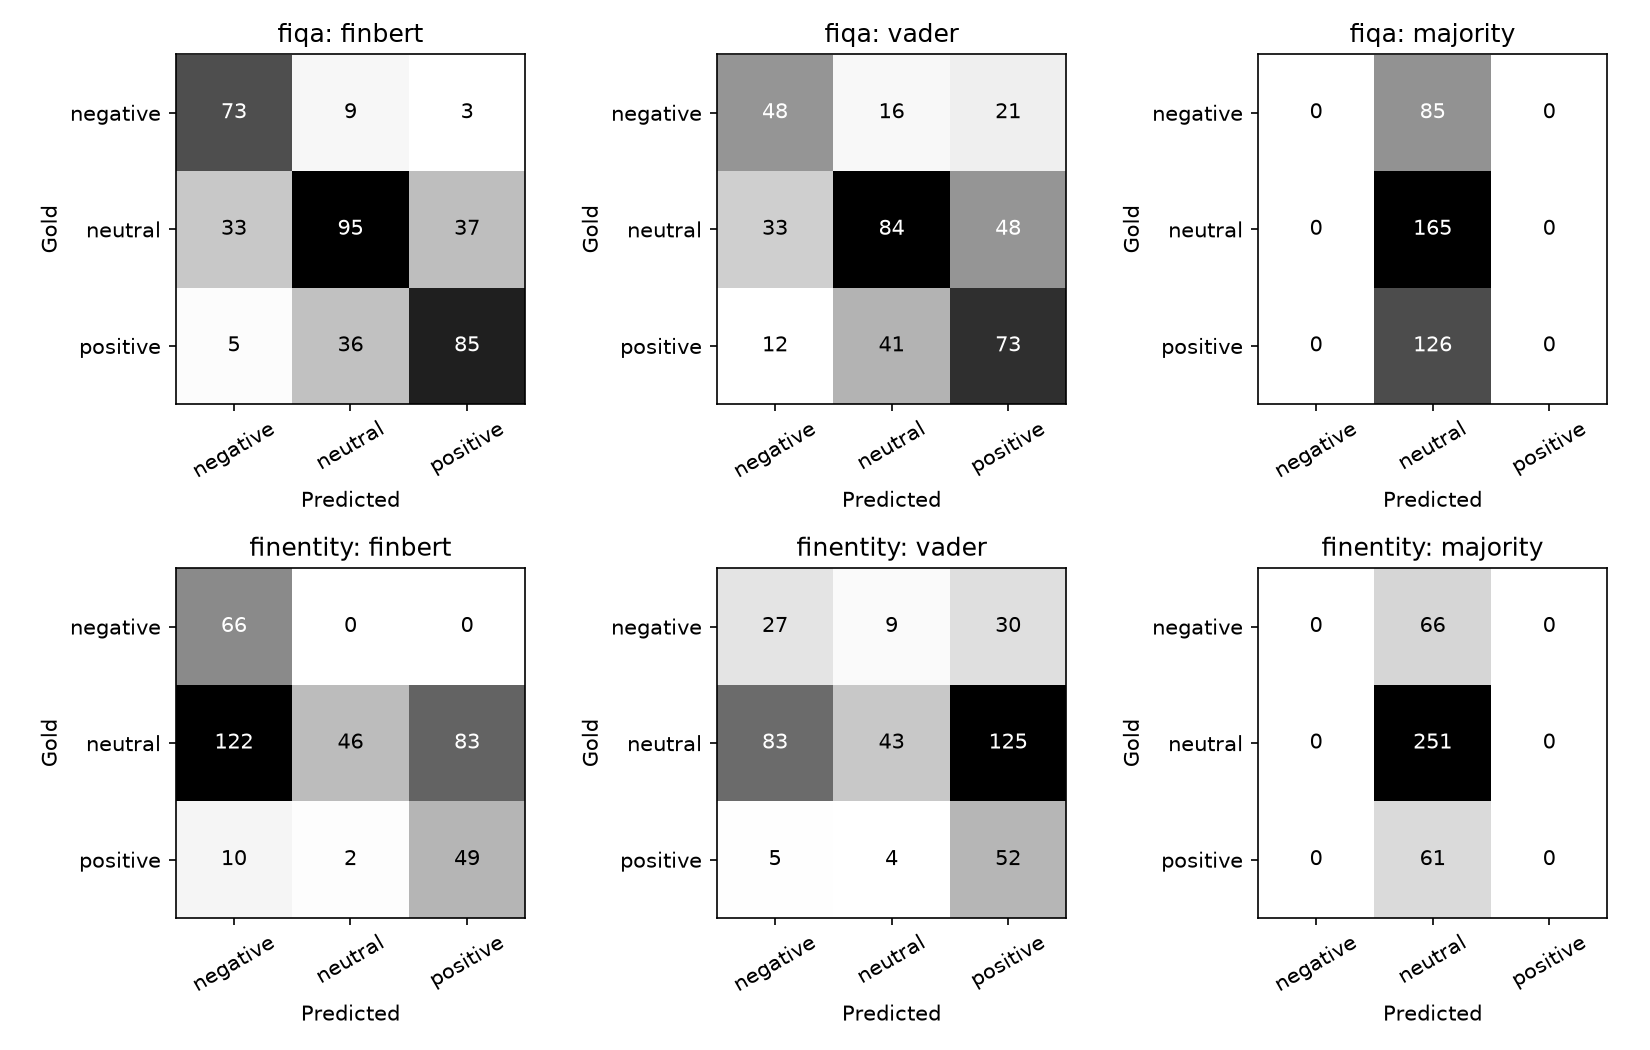

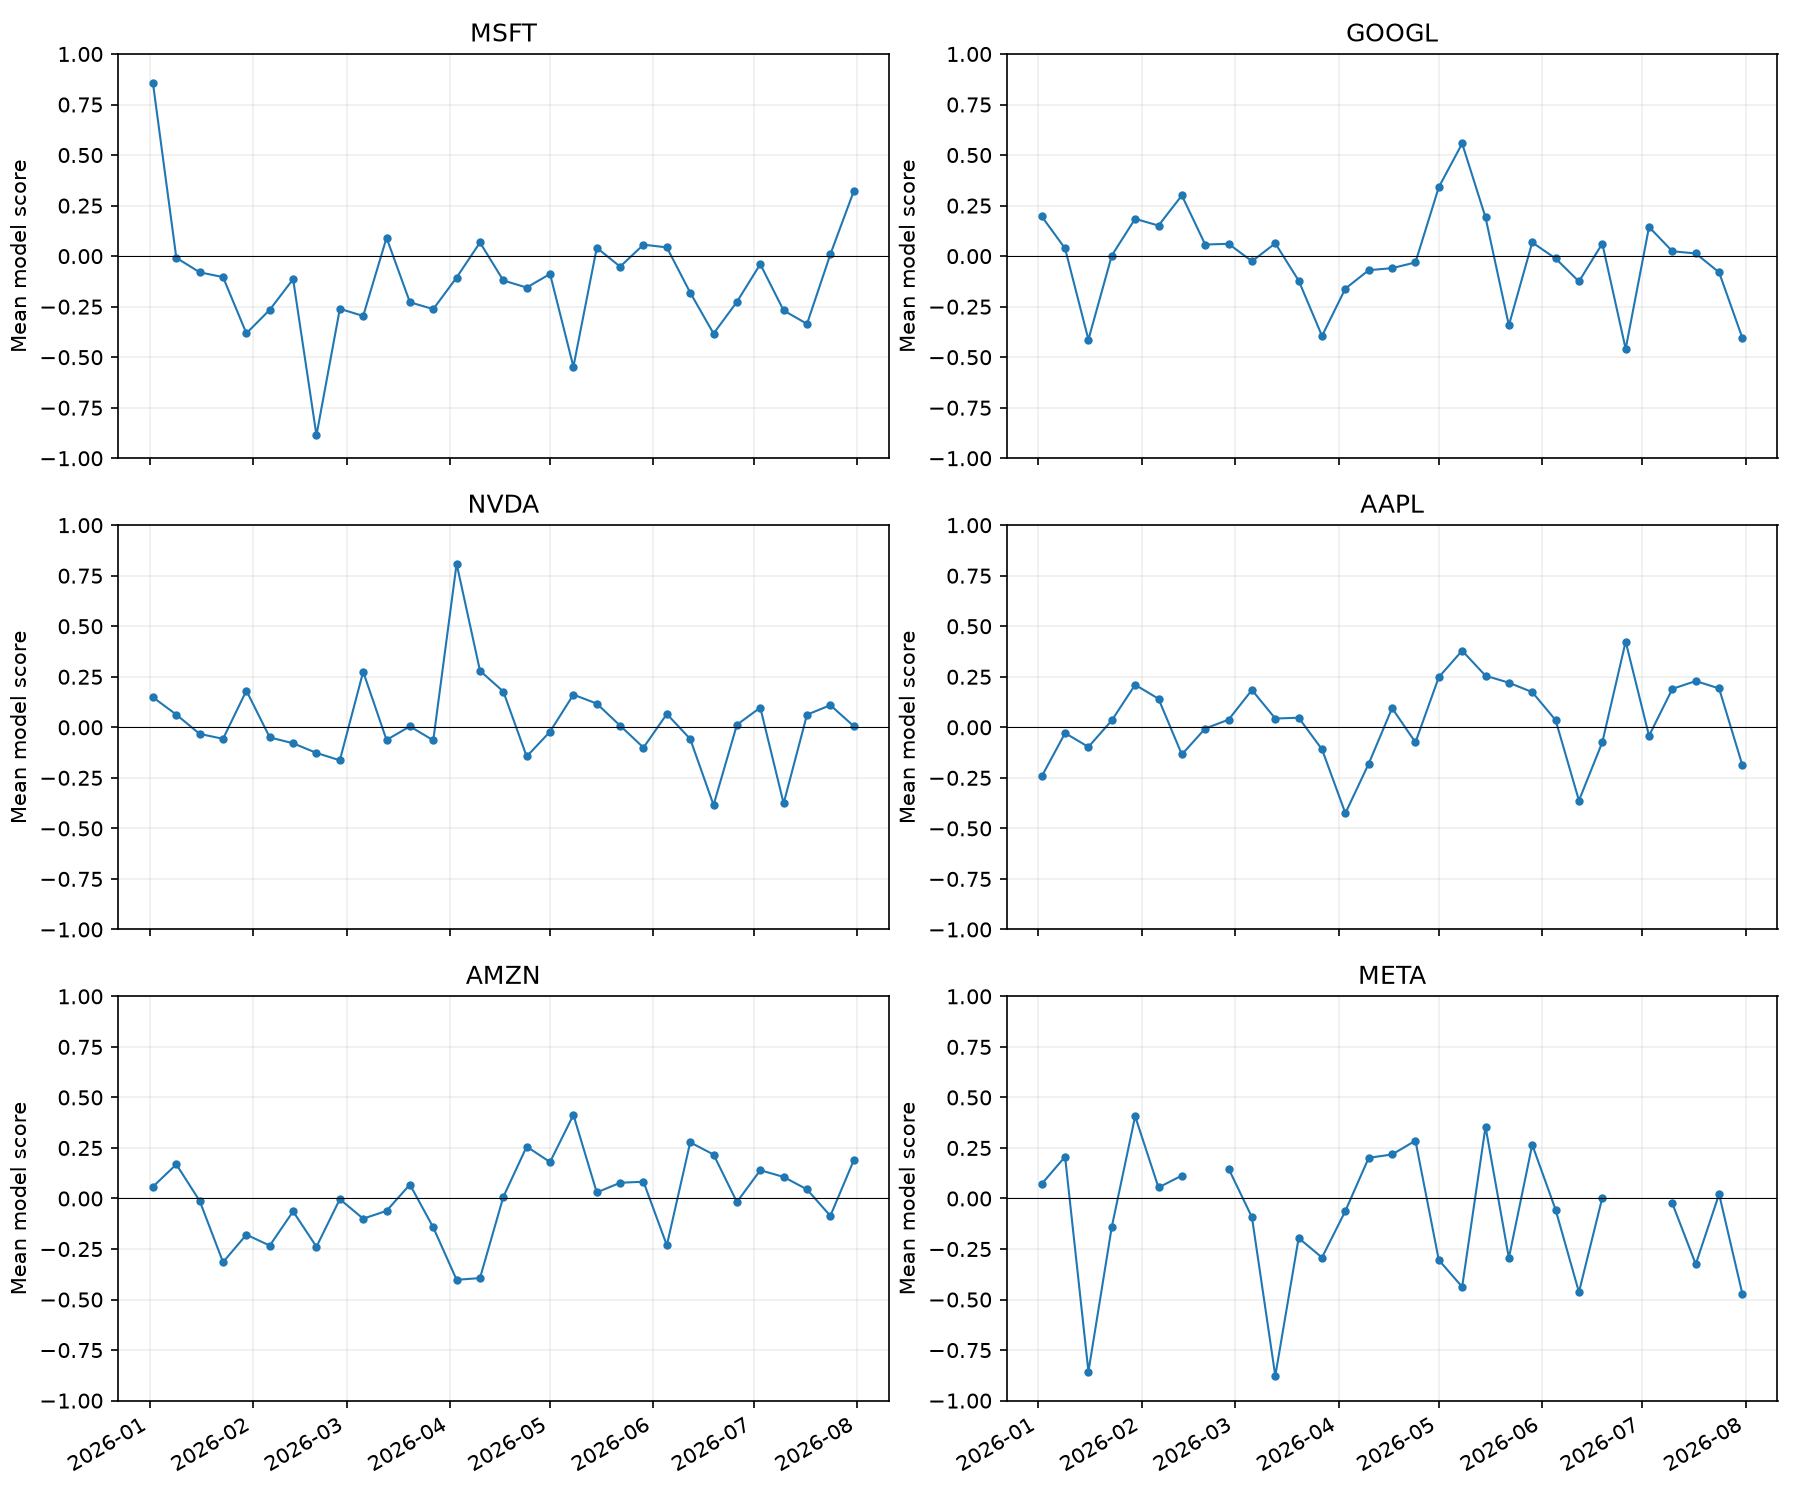

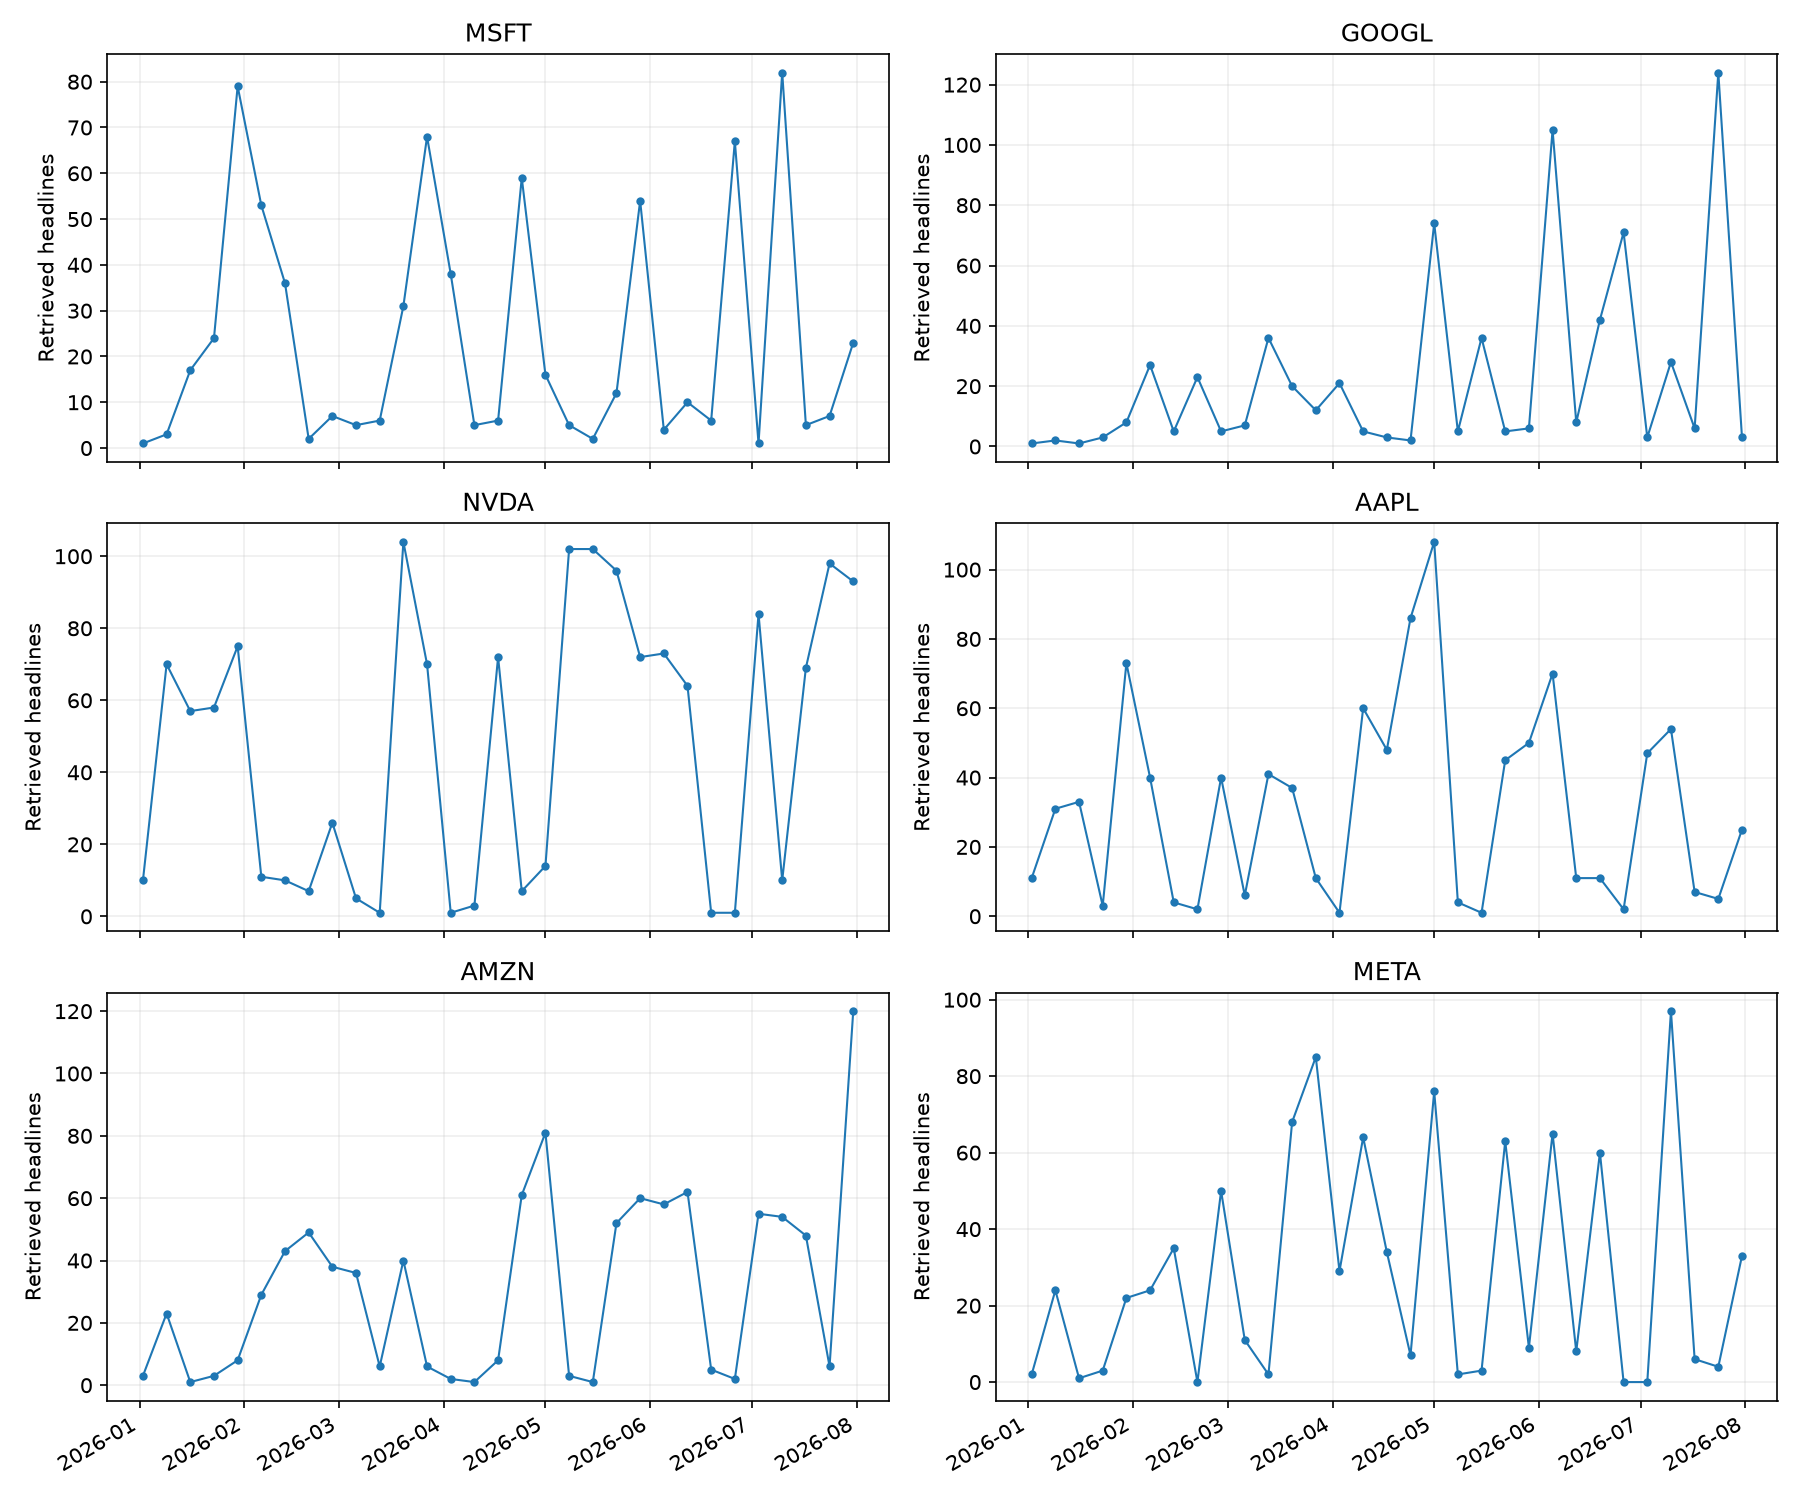

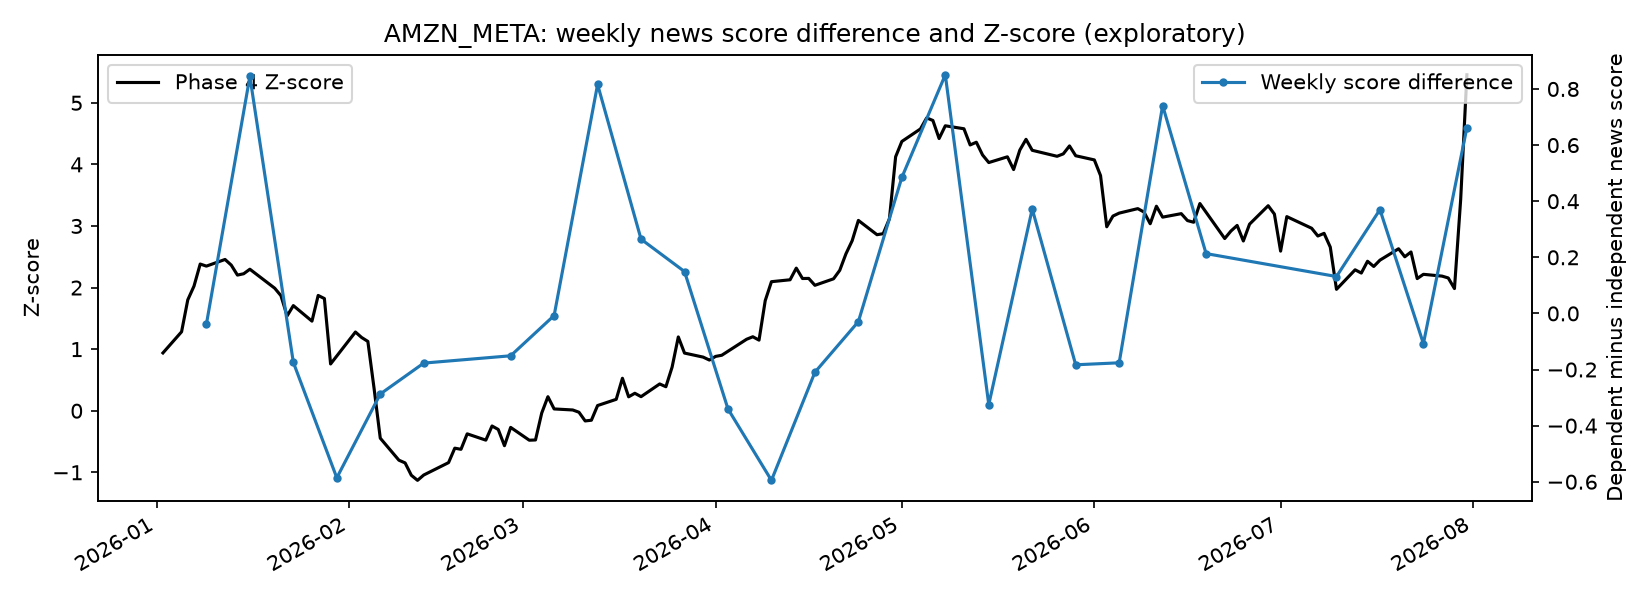

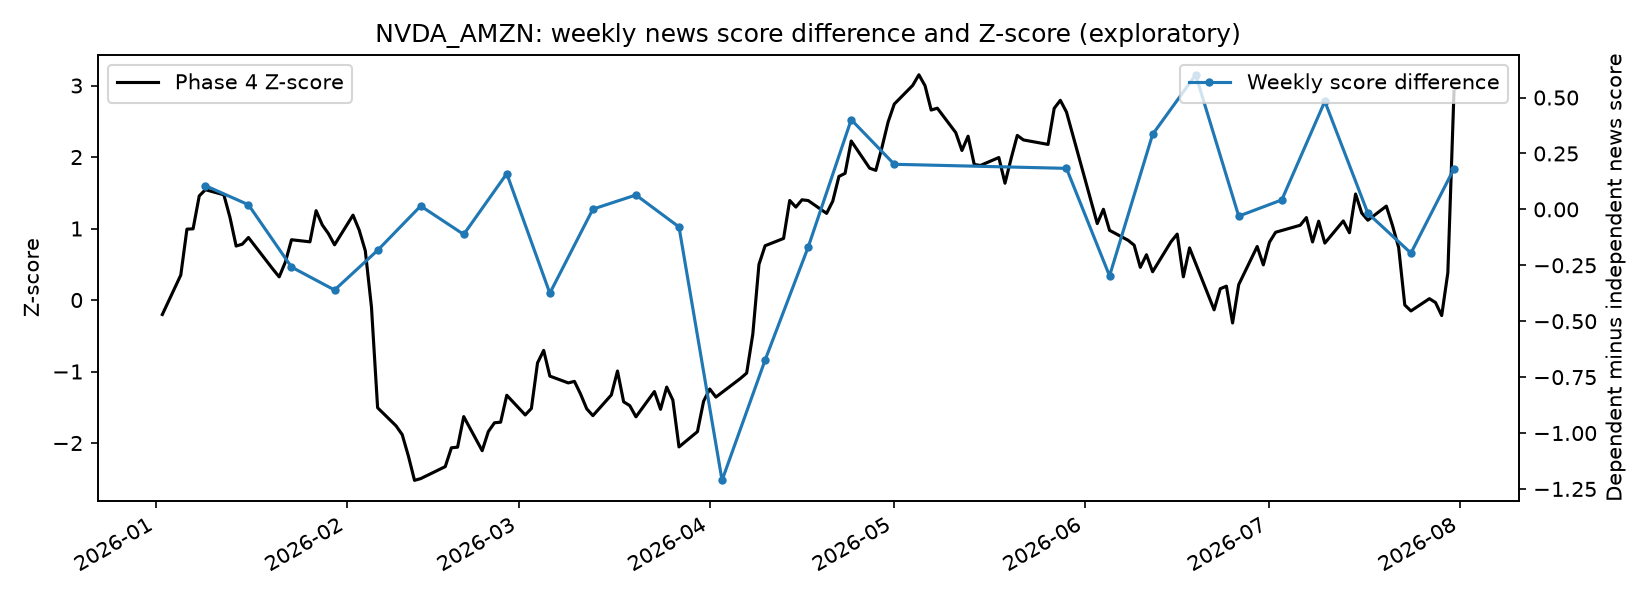

In [8]:
from IPython.display import Image, display
figure_path = root / settings["paths"]["figures"]
for name in ["benchmark_confusion_matrices.png", "weekly_sentiment.png", "weekly_coverage.png", "AMZN_META_news_and_zscore.png", "NVDA_AMZN_news_and_zscore.png"]:
    display(Image(filename=str(figure_path / name)))

## Limits

The collection is a sample of indexed financial coverage, with query, relevance, and duplicate rules affecting what remains. Google's results for a wide window and for its parts do not add up, so counts depend on how the windows were split. Retrospective RSS collection cannot establish what was available at a past prediction time. Date-only items support date summaries, not intraday timing claims. FinBERT probabilities are model outputs, and the two external benchmarks do not establish accuracy on the collected news. Findings and verification records are linked from `docs/phase_planning/sentiment_analysis.md`.